# SusFoodDetector 🤨: Food Adulteration Risk Predictor

This notebook demonstrates a structured machine learning pipeline designed to identify food adulteration risks across restaurants. We compare a baseline heuristic, a Linear Model (Logistic Regression), and a Gradient Boosting Tree model (LightGBM) to find out who is serving straight facts and who is capped.

```markdown
## Step 1: Libraries and Data Loading
We start by importing our essential data science and ML libraries, loading the structured dataset, and setting up the appropriate data splits.
```

In [ ]:
import pandas as pd
import numpy as np
import lightgbm as lgb
import shap
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    classification_report,
    confusion_matrix
)

# Set random seed for reproducibility
np.random.seed(42)

# Load dataset
df = pd.read_csv("data/training_items_flat.csv")
print(f"Dataset loaded: {len(df)} rows")
print(f"Overall baseline positive rate (adulterated): {df['is_adulterated'].mean():.3%}")

Dataset loaded: 126851 rows
Overall baseline positive rate (adulterated): 17.874%


```markdown
## Step 2: Feature Engineering & Splits
We separate our features from identifiers/labels and divide the data into training, validation, and test sets according to the preset `split` attribute.
```

In [ ]:
# Define targets and drop metadata/leakage columns
y = df["is_adulterated"]
X = df.drop(columns=["is_adulterated", "adulterant_detected", "item_id",
                     "restaurant_id", "location_id", "split"])

# Identify and format categorical columns
cat_cols = list(X.select_dtypes("object").columns)
X[cat_cols] = X[cat_cols].astype("category")

# Define boolean indices for splits
tr = (df["split"] == "train")
va = (df["split"] == "val")
te = (df["split"] == "test")

print(f"Train size: {tr.sum()} | Val size: {va.sum()} | Test size: {te.sum()}")

Train size: 89959 | Val size: 17870 | Test size: 19022


```markdown
## Step 3: Model Training
We train two models on the training dataset:
1. **Logistic Regression (Linear Benchmark):** Requires categorical variables to be One-Hot Encoded and numeric variables scaled.
2. **LightGBM (Gradient Boosting Classifier):** Directly handles raw categorical features and uses early stopping on the validation set to prevent overfitting.
```

In [ ]:
# --- 1. Logistic Regression Setup ---
X_oh = pd.get_dummies(X, columns=cat_cols).fillna(-1)
mu, sd = X_oh[tr].mean(), X_oh[tr].std() + 1e-9

print("Training Logistic Regression...")
lr = LogisticRegression(max_iter=2000, C=0.5)
lr.fit((X_oh[tr] - mu) / sd, y[tr])

# --- 2. LightGBM Setup ---
print("\nTraining LightGBM Classifier...")
model = lgb.LGBMClassifier(
    n_estimators=2000,
    learning_rate=0.03,
    num_leaves=63,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    random_state=42,
    verbose=-1
)

model.fit(
    X[tr], y[tr],
    eval_set=[(X[va], y[va])],
    eval_metric="auc",
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(200)]
)

Training Logistic Regression...

Training LightGBM Classifier...
Training until validation scores don't improve for 100 rounds
[200]	valid_0's auc: 0.90135	valid_0's binary_logloss: 0.26981
[400]	valid_0's auc: 0.902145	valid_0's binary_logloss: 0.267851
Early stopping, best iteration is:
[449]	valid_0's auc: 0.902448	valid_0's binary_logloss: 0.267561


LGBMClassifier(colsample_bytree=0.8, learning_rate=0.03, n_estimators=2000,
               num_leaves=63, random_state=42, subsample=0.8, subsample_freq=1,
               verbose=-1)

```markdown
## Step 4: Performance Evaluation (On Test Partition)
We generate predictions on our unseen test set and compare the models against a simplistic price-based rule.
```

In [ ]:
# Predict probabilities on test partition
p_lr = lr.predict_proba((X_oh[te] - mu) / sd)[:, 1]
p_gbm = model.predict_proba(X[te])[:, 1]

def build_metrics_row(name, p):
    return {
        "model": name,
        "ROC-AUC": roc_auc_score(y[te], p),
        "PR-AUC": average_precision_score(y[te], p)
    }

# Build comparative summary dataframe
metrics_summary = pd.DataFrame([
    build_metrics_row("Price-only rule (Heuristic)", -X[te]["price_ratio_to_peer_median"]),
    build_metrics_row("Logistic Regression", p_lr),
    build_metrics_row("LightGBM", p_gbm)
])

display(metrics_summary.round(4))
print(f"Random Class Baseline PR-AUC: {y[te].mean():.3f}")

,model,ROC-AUC,PR-AUC
0,Price-only rule (Heuristic),0.7392,0.4858
1,Logistic Regression,0.8975,0.7534
2,LightGBM,0.9025,0.7617


Random Class Baseline PR-AUC: 0.187


```markdown
## Step 5: Optimization & Calibration (Threshold Tuning)
Using the validation set probabilities, we find the decision threshold that maximizes the F1-Score, then apply it to classify the test set.
```

In [ ]:
# Predict validation probabilities
p_val = model.predict_proba(X[va])[:, 1]
prec, rec, thr = precision_recall_curve(y[va], p_val)

# Pick optimal threshold based on maximum F1-Score
f1_scores = 2 * prec * rec / (prec + rec + 1e-9)
thr_best = thr[f1_scores[:-1].argmax()]

# Map predictions to optimal threshold on the test set
pred_test = (p_gbm >= thr_best).astype(int)

print(f"Optimized Threshold picked on Validation: {thr_best:.3f}\n")
print("--- Test Set Classification Report ---")
print(classification_report(y[te], pred_test, digits=3))

print("--- Test Set Confusion Matrix ---")
print(confusion_matrix(y[te], pred_test))

Optimized Threshold picked on Validation: 0.309

--- Test Set Classification Report ---
              precision    recall  f1-score   support

           0      0.929     0.917     0.923     15474
           1      0.656     0.695     0.675      3548

    accuracy                          0.875     19022
   macro avg      0.793     0.806     0.799     19022
weighted avg      0.878     0.875     0.877     19022

--- Test Set Confusion Matrix ---
[[14183  1291]
 [ 1081  2467]]


```markdown
## Step 6: Model Explainability with SHAP
We use SHAP values to visualize the global impacts of the features as well as local individual predictions.
```

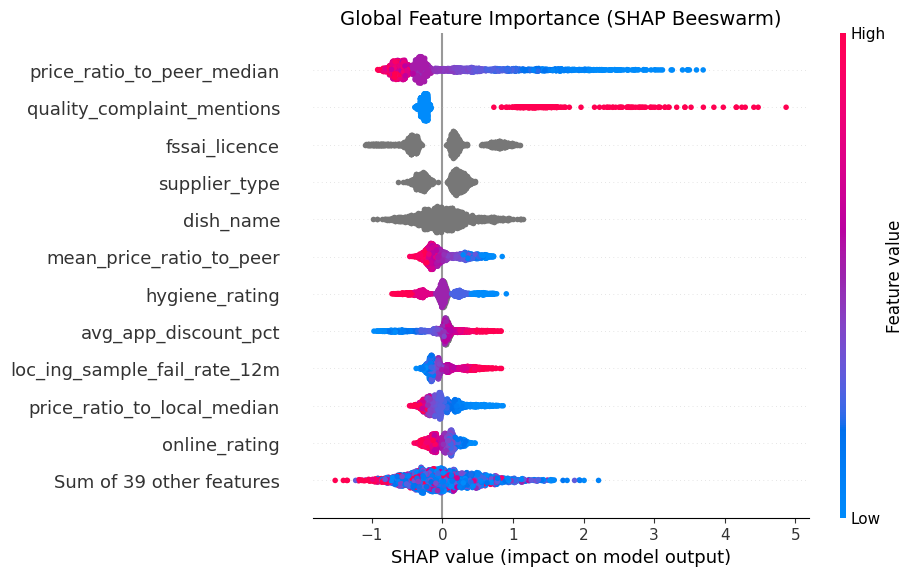

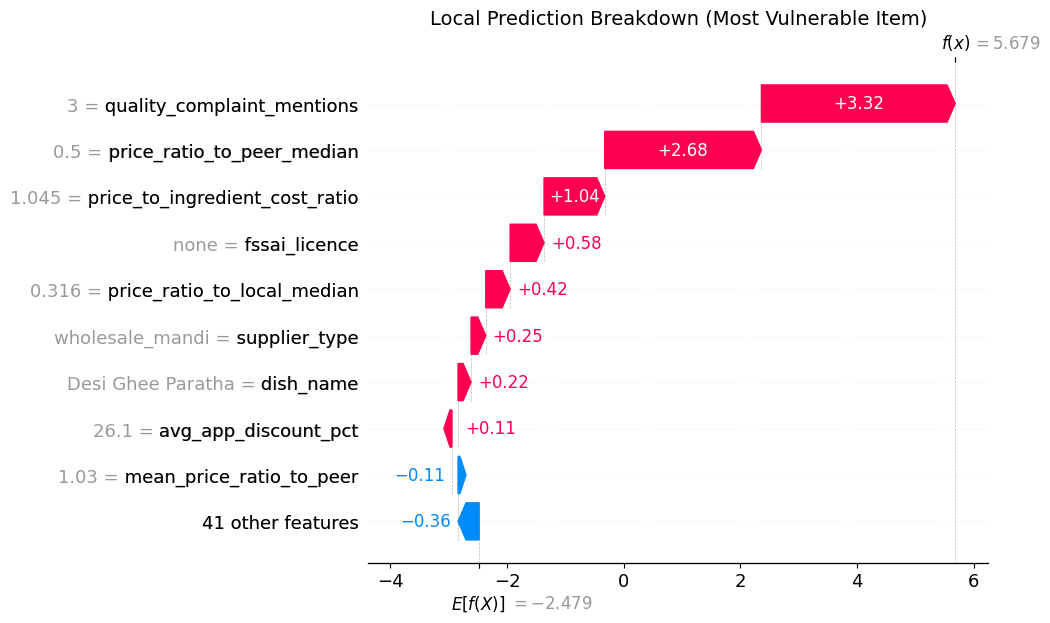

In [ ]:
# Calculate SHAP values on a test sample
explainer = shap.TreeExplainer(model)
sample_test = X[te].sample(2000, random_state=42)
sv = explainer(sample_test)

# Adjust array dimensions if multi-class representation is outputted
if sv.values.ndim == 3:
    sv = sv[:, :, 1]

# Global Importance plot
plt.figure(figsize=(10, 6))
shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title("Global Feature Importance (SHAP Beeswarm)", fontsize=14)
plt.show()

# Local instance plot (Most extreme probability item)
high_risk_idx = int(np.argmax(model.predict_proba(sample_test)[:, 1]))
plt.figure(figsize=(10, 5))
shap.plots.waterfall(sv[high_risk_idx], max_display=10, show=False)
plt.title("Local Prediction Breakdown (Most Vulnerable Item)", fontsize=14)
plt.show()

```markdown
## Step 7: Business Implementation & Risk Ranking
Finally, we map our item predictions back to their corresponding establishments to provide a target list of high-risk restaurants for resource optimization.
```

In [ ]:
rest_meta = pd.read_csv("data/restaurants.csv")

# Aggregate item-level risk predictions up to restaurant level
test_predictions = df[te].assign(p=p_gbm)
restaurant_rankings = (
    test_predictions.groupby("restaurant_id")["p"].max().rename("risk_score").reset_index()
    .merge(
        rest_meta[["restaurant_id", "restaurant_name", "restaurant_type", "any_adulterated", "risk_level"]],
        on="restaurant_id"
    )
    .sort_values("risk_score", ascending=False)
)

# Calculate Inspector Hit Rates (Inspection Precision Lift)
base_prevalence = restaurant_rankings["any_adulterated"].mean()
for k in (50, 100, 200):
    hit_rate = restaurant_rankings.head(k)["any_adulterated"].mean()
    print(f"Inspect top {k:3d} restaurants: {hit_rate:4.0%} truly adulterated vs {base_prevalence:4.0%} random ({hit_rate/base_prevalence:.2f}x lift)")

print("\n--- Top 10 High-Risk Establishments for Prioritized Inspection ---")
display(restaurant_rankings.head(10))

Inspect top  50 restaurants: 100% truly adulterated vs  75% random (1.33x lift)
Inspect top 100 restaurants: 100% truly adulterated vs  75% random (1.33x lift)
Inspect top 200 restaurants: 100% truly adulterated vs  75% random (1.33x lift)

--- Top 10 High-Risk Establishments for Prioritized Inspection ---


,restaurant_id,risk_score,restaurant_name,restaurant_type,any_adulterated,risk_level
342,R02442,0.997877,Green Palace,dhaba,1,high
78,R00772,0.996996,Amrit Mithai Bhandar,sweet_shop,1,high
467,R03162,0.996595,Taj Darbar,street_stall,1,medium
1084,R07238,0.996417,Taj Restaurant,casual_dining,1,high
911,R06054,0.996332,Punjabi Dhaba,dhaba,1,high
478,R03231,0.996173,Ganesh Cafe,street_stall,1,high
845,R05689,0.995909,Delhi Express,dhaba,1,high
1031,R06884,0.995809,Kwality Treats,street_stall,1,high
649,R04384,0.995053,Hari Express,sweet_shop,1,high
883,R05905,0.995018,Lakshmi Tadka,dhaba,1,high


In [ ]:
from google.colab import files
files.upload()   # select generate_dataset.py

Saving generate_dataset.py to generate_dataset.py


{'generate_dataset.py': b'#!/usr/bin/env python3\r\n"""\r\nSynthetic dataset generator: restaurant food-adulteration risk.\r\n\r\nIdea\r\n----\r\nFood-safety officers can\'t test every restaurant. But adulteration is not random:\r\n  * some locations have known rackets for specific items (paneer, khoya, ghee, soya ...)\r\n  * restaurants whose menus lean on those items are more exposed\r\n  * an item priced unusually low vs. peers (or vs. the raw ingredient cost) is suspicious\r\n  * licence status, hygiene rating, complaints, supplier type etc. add signal\r\n\r\nThis script builds a hidden "ground truth" from those mechanisms, then exposes only the\r\nobservable features plus the lab-test label, so a model has to learn the relationships.\r\n\r\nStdlib only. Usage:\r\n    python3 generate_dataset.py --restaurants 8000 --seed 42 --out data\r\n"""\r\nimport argparse\r\nimport csv\r\nimport math\r\nimport os\r\nimport random\r\nimport statistics\r\nfrom collections import defaultdict\r\n\

In [ ]:
!python generate_dataset.py --restaurants 8000 --seed 42 --out data
!ls -lh data

locations=120 restaurants=8000 items=126851
item positive rate=0.179  restaurants with any adulteration=0.741
  risk_level=low: 2070
  risk_level=medium: 3331
  risk_level=high: 2599
total 53M
-rw-r--r-- 1 root root 5.4K Oct 21 18:51 dishes.csv
-rw-r--r-- 1 root root  868 Oct 21 18:51 ingredients.csv
-rw-r--r-- 1 root root  85K Oct 21 18:51 location_ingredient_stats.csv
-rw-r--r-- 1 root root  11K Oct 21 18:51 locations.csv
-rw-r--r-- 1 root root  13M Oct 21 18:51 menu_items.csv
-rw-r--r-- 1 root root 1.4M Oct 21 18:51 restaurants.csv
-rw-r--r-- 1 root root  40M Oct 21 18:51 training_items_flat.csv


rows: 126851 | positive rate: 0.179
Training until validation scores don't improve for 100 rounds
[200]	valid_0's auc: 0.90135	valid_0's binary_logloss: 0.26981
[400]	valid_0's auc: 0.902145	valid_0's binary_logloss: 0.267851
Early stopping, best iteration is:
[449]	valid_0's auc: 0.902448	valid_0's binary_logloss: 0.267561
              model  ROC-AUC  PR-AUC
    Price-only rule   0.7392  0.4858
Logistic Regression   0.8975  0.7534
           LightGBM   0.9025  0.7617
random PR-AUC = 0.187

threshold = 0.309
              precision    recall  f1-score   support

           0      0.929     0.917     0.923     15474
           1      0.656     0.695     0.675      3548

    accuracy                          0.875     19022
   macro avg      0.793     0.806     0.799     19022
weighted avg      0.878     0.875     0.877     19022

[[14183  1291]
 [ 1081  2467]]


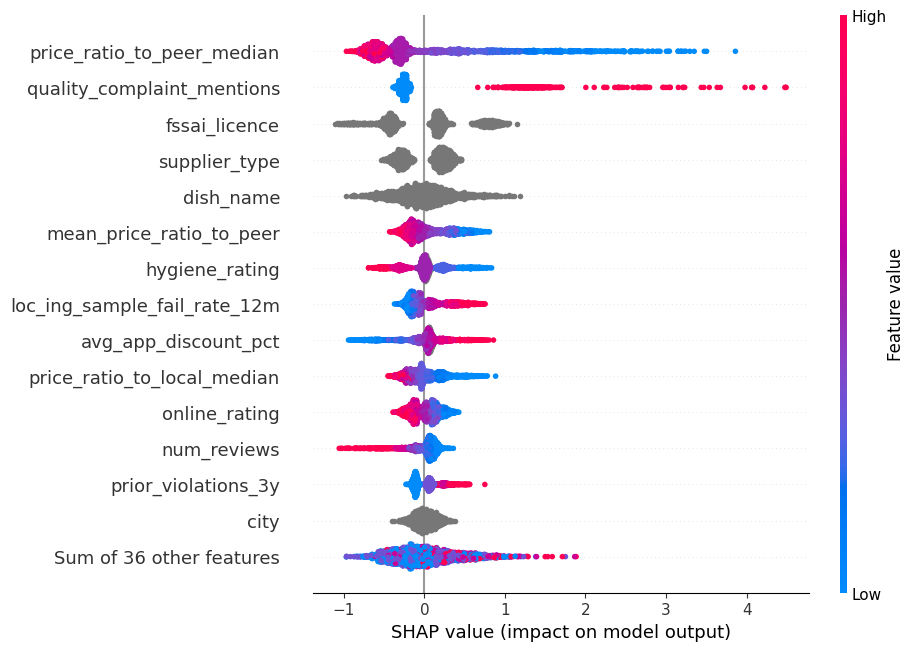

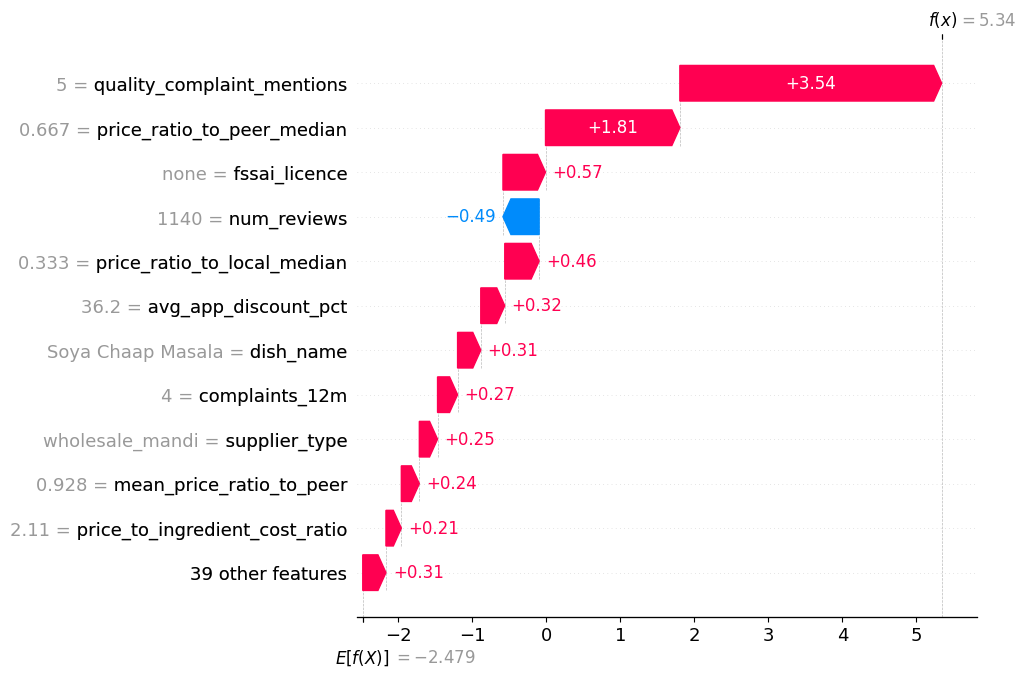

Inspect top 50: 100% truly adulterated vs 75% random  (1.3x lift)
Inspect top 100: 100% truly adulterated vs 75% random  (1.3x lift)
Inspect top 200: 100% truly adulterated vs 75% random  (1.3x lift)


,restaurant_id,risk_score,restaurant_name,restaurant_type,any_adulterated,risk_level
342,R02442,0.997877,Green Palace,dhaba,1,high
78,R00772,0.996996,Amrit Mithai Bhandar,sweet_shop,1,high
467,R03162,0.996595,Taj Darbar,street_stall,1,medium
1084,R07238,0.996417,Taj Restaurant,casual_dining,1,high
911,R06054,0.996332,Punjabi Dhaba,dhaba,1,high
478,R03231,0.996173,Ganesh Cafe,street_stall,1,high
845,R05689,0.995909,Delhi Express,dhaba,1,high
1031,R06884,0.995809,Kwality Treats,street_stall,1,high
649,R04384,0.995053,Hari Express,sweet_shop,1,high
883,R05905,0.995018,Lakshmi Tadka,dhaba,1,high


In [ ]:
!pip -q install shap
import pandas as pd, numpy as np, lightgbm as lgb, shap, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             classification_report, confusion_matrix)

df = pd.read_csv("data/training_items_flat.csv")
y = df["is_adulterated"]
X = df.drop(columns=["is_adulterated", "adulterant_detected", "item_id",
                     "restaurant_id", "location_id", "split"])
cat_cols = list(X.select_dtypes("object").columns)
X[cat_cols] = X[cat_cols].astype("category")

tr, va, te = (df["split"] == s for s in ("train", "val", "test"))
print("rows:", len(df), "| positive rate:", round(y.mean(), 3))
X_oh = pd.get_dummies(X, columns=cat_cols).fillna(-1)
mu, sd = X_oh[tr].mean(), X_oh[tr].std() + 1e-9
lr = LogisticRegression(max_iter=2000, C=0.5).fit((X_oh[tr] - mu) / sd, y[tr])
p_lr = lr.predict_proba((X_oh[te] - mu) / sd)[:, 1]
model = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.03, num_leaves=63,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                           random_state=42, verbose=-1)
model.fit(X[tr], y[tr], eval_set=[(X[va], y[va])], eval_metric="auc",
          callbacks=[lgb.early_stopping(100), lgb.log_evaluation(200)])
p_gbm = model.predict_proba(X[te])[:, 1]

def row(name, p): return {"model": name, "ROC-AUC": roc_auc_score(y[te], p),
                          "PR-AUC": average_precision_score(y[te], p)}
print(pd.DataFrame([row("Price-only rule", -X[te]["price_ratio_to_peer_median"]),
                    row("Logistic Regression", p_lr),
                    row("LightGBM", p_gbm)]).round(4).to_string(index=False))
print("random PR-AUC =", round(y[te].mean(), 3))

# threshold picked on validation, applied to test
p_val = model.predict_proba(X[va])[:, 1]
prec, rec, thr = precision_recall_curve(y[va], p_val)
thr_best = thr[(2 * prec * rec / (prec + rec + 1e-9))[:-1].argmax()]
pred = (p_gbm >= thr_best).astype(int)
print(f"\nthreshold = {thr_best:.3f}")
print(classification_report(y[te], pred, digits=3))
print(confusion_matrix(y[te], pred))

explainer = shap.TreeExplainer(model)
sample = X[te].sample(2000, random_state=0)
sv = explainer(sample)
if sv.values.ndim == 3:            # some shap versions return both classes
    sv = sv[:, :, 1]

shap.plots.beeswarm(sv, max_display=15)        # global: what drives risk overall

i = int(np.argmax(model.predict_proba(sample)[:, 1]))
shap.plots.waterfall(sv[i], max_display=12)    # local: why THIS item was flagged


rest = pd.read_csv("data/restaurants.csv")
t = df[te].assign(p=p_gbm)
rank = (t.groupby("restaurant_id")["p"].max().rename("risk_score").reset_index()
          .merge(rest[["restaurant_id", "restaurant_name", "restaurant_type",
                       "any_adulterated", "risk_level"]], on="restaurant_id")
          .sort_values("risk_score", ascending=False))

base = rank.any_adulterated.mean()
for k in (50, 100, 200):
    hit = rank.head(k).any_adulterated.mean()
    print(f"Inspect top {k}: {hit:.0%} truly adulterated vs {base:.0%} random  ({hit/base:.1f}x lift)")
rank.head(10)
